# How we get the optimum keff: K0s, robust rDCA and charge balance

*TPC space-charge keff tuning, per run. Everything is a factor **keff_new / keff_CDB** on the CDB keff.*

**The idea.** For a set of runs we re-reconstruct the same events at four values of keff and measure which value gives the narrowest K0s peak and the highest K0s significance (the **measured optimum**). For a new run we have no scan, only its production reconstruction, so we look for observables of that reconstruction that predict the optimum: the **robust rDCA offset** between positive and negative tracks, and the **charge balance** and its pT dependence. A leave-one-out calibration turns them into a recipe with an error.

**Result in one paragraph.** In pp the optimum is predicted to ±0.02 (rms), against 0.035 for a constant; the charge-balance pT dependence is the most precise predictor (r = +0.87), the robust rDCA is nearly as good (r = −0.80) and the weighted average of the two is the best (rms 0.019). In O+O the per-run K0s optimum is known only to ±0.05, comparable to the spread of the optima, so the recipe can be shown to agree in sign (rDCA: r = −0.42; pooled groups 2–4σ) but not yet to beat a constant per run (section 1.6).

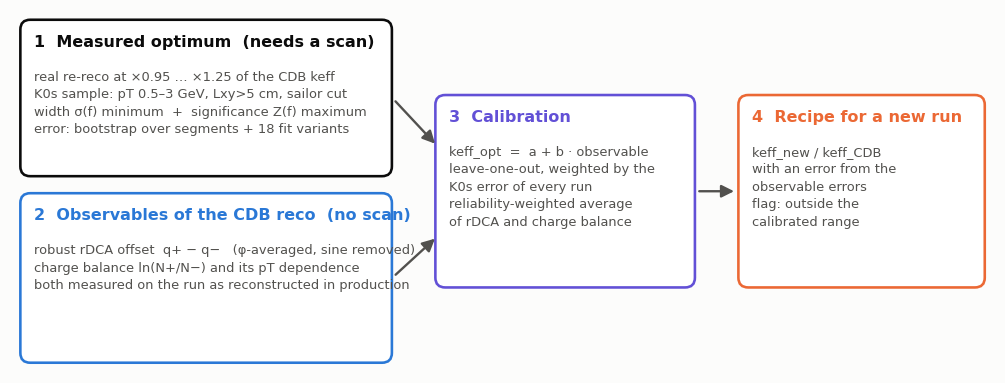

In [1]:
import os; os.environ['KSEL_SUF'] = 'n'
import sys, pickle, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, '/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/ml/newgain/v0keffscan')
import keffmethod_plots as M, keffstudy_plots as KP, kscan5_corr as KC, kscan5_plot as K5, keffcombo as KB, recal as RC
G, Ro = KC.feats(); D, Rall, Rm = KP.obs_tables(); Opp, Ooo = KC.optima('pp'), KC.optima('oo'); ppr = KP.pp_robust(); ms = KP.models(G, Ro, Opp, Ooo, Rm, ppr)
M.fig_flow(); plt.show()

## 1  The K0s measurement

**Sample.** K0s candidates of the V0 finder with the "sailor" cut, mass within ±60 MeV of the PDG value, **K0s pT 0.5–3 GeV and decay length Lxy > 5 cm**. The decay-length cut removes the combinatorial background that dominates in O+O at short decay length (section 1.5). Every keff point uses the **same segments and the same events**.

**Width and significance.** For each keff point the mass histogram (1 MeV bins) is fitted with a Gaussian plus a line. σ is the Gaussian width; the significance is Z = S/√(S+B) with S and B the Gaussian and background integrals in a ±2σ window (shaded). The optimum is the **vertex of a parabola** through σ(f) (minimum) or Z(f) (maximum).

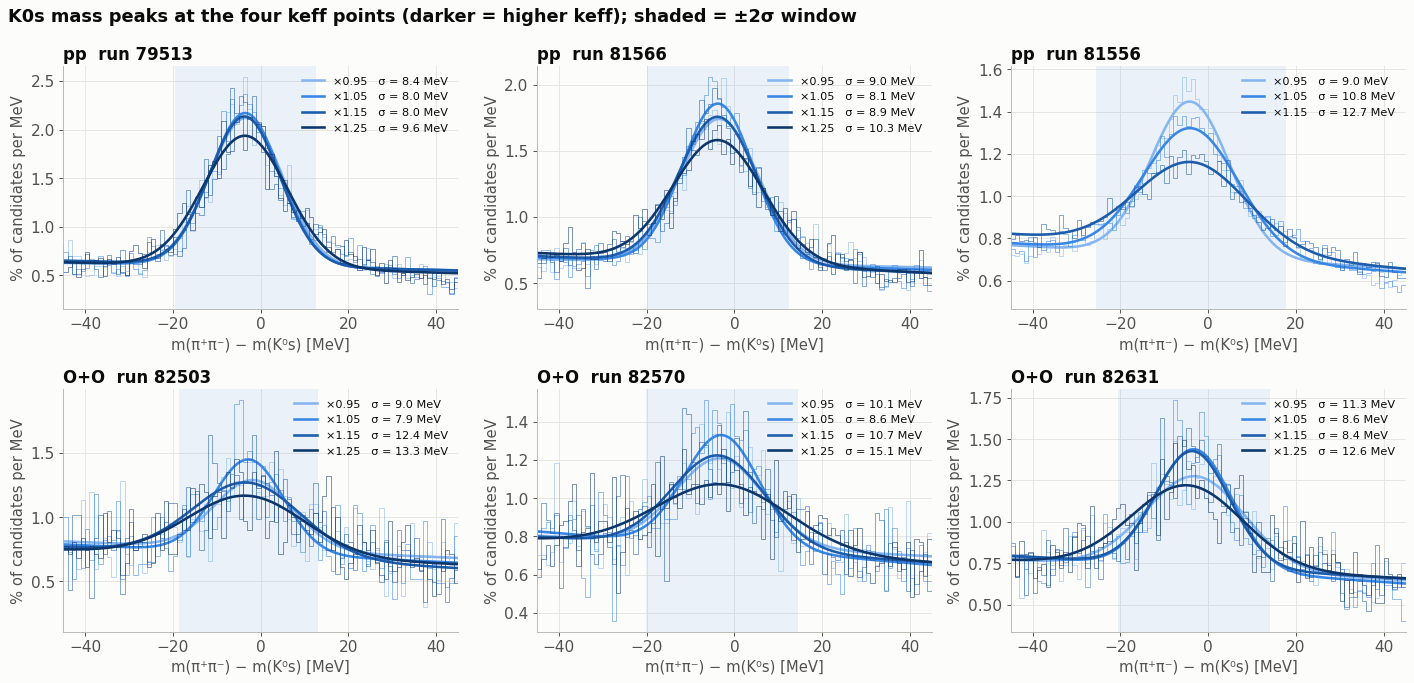

In [2]:
M.fig_mass_examples([('pp', 79513), ('pp', 81566), ('pp', 81556), ('oo', 82503), ('oo', 82570), ('oo', 82631)], 'K0s mass peaks at the four keff points (darker = higher keff); shaded = ±2σ window'); plt.show()

Reading: in 79513 (low current) the peak is narrowest around ×1.05, in 81556 (highest current) it only gets worse with increasing keff, so the optimum is at or below the lowest point of the scan.

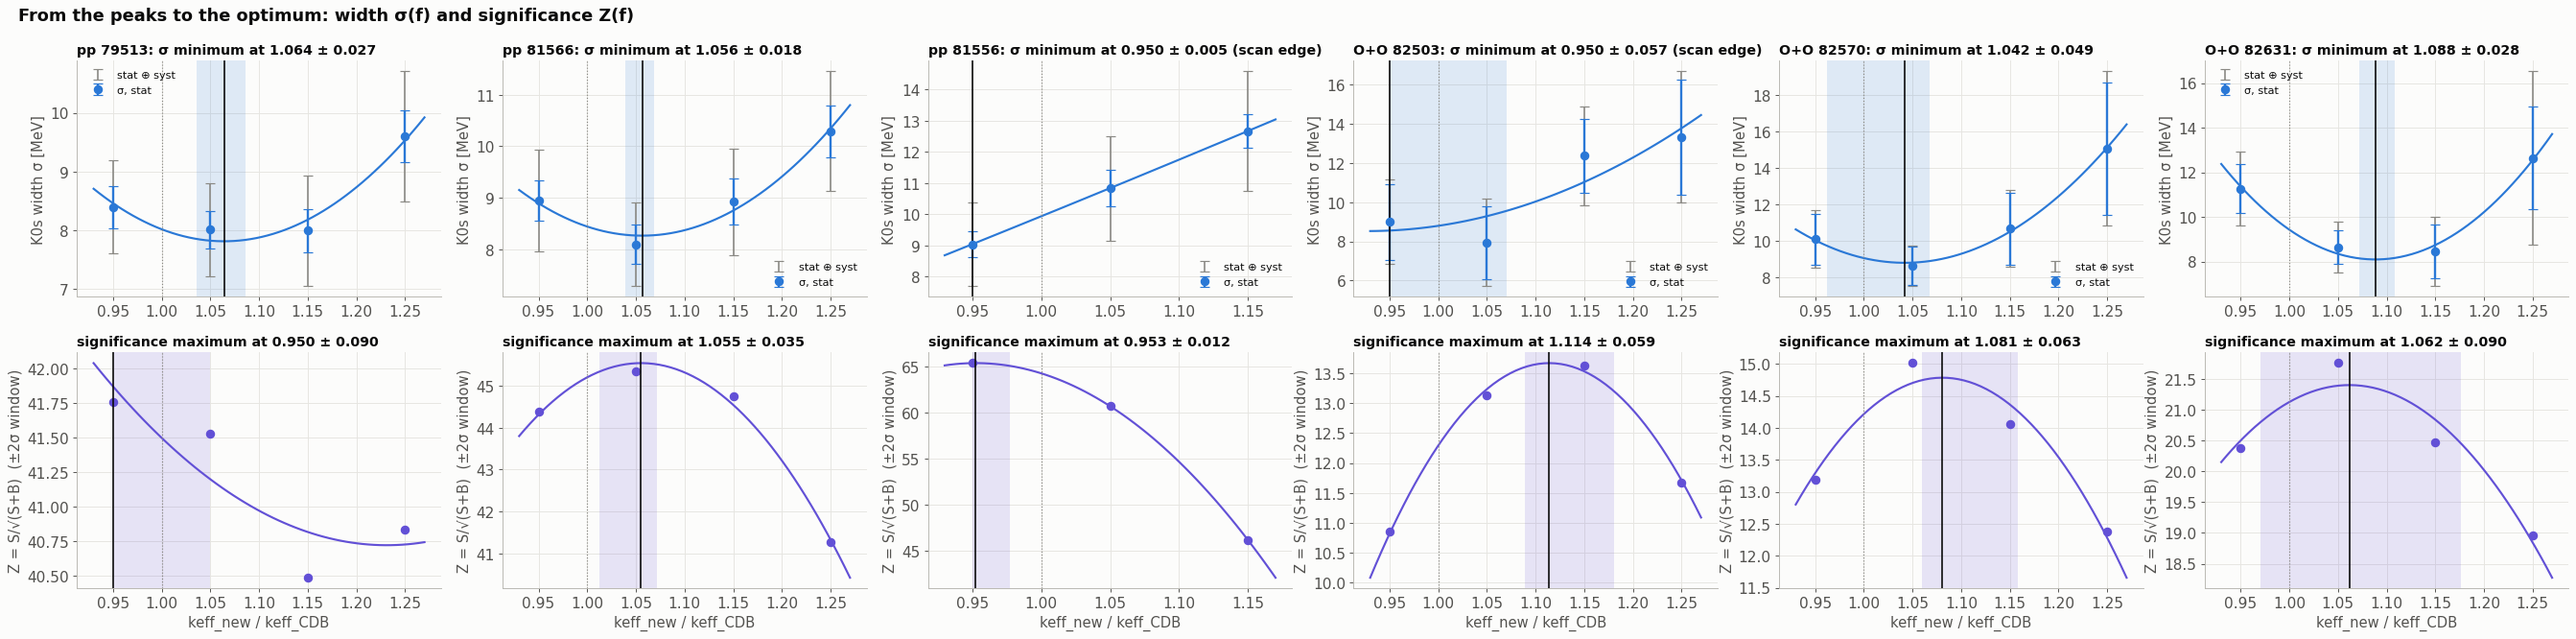

In [3]:
M.fig_opt_curves([('pp', 79513), ('pp', 81566), ('pp', 81556), ('oo', 82503), ('oo', 82570), ('oo', 82631)], 'From the peaks to the optimum: width σ(f) and significance Z(f)'); plt.show()

### Errors on the optimum
* **Statistical:** bootstrap over segments. The same resample is used at every keff point, so the correlation between points (same events) is kept.
* **Systematic:** 18 variants of the width fit (bin 0.5 / 1 / 2 MeV × fit range 35 / 45 / 60 MeV × linear / quadratic background). In pp the systematic spread of σ (median 0.85 MeV) exceeds the statistical one (0.34 MeV), but it is almost the same shift at all points, so it moves the **optimum** by only 0.007; in O+O the two are comparable (optimum: 0.06 systematic, 0.08 statistical).

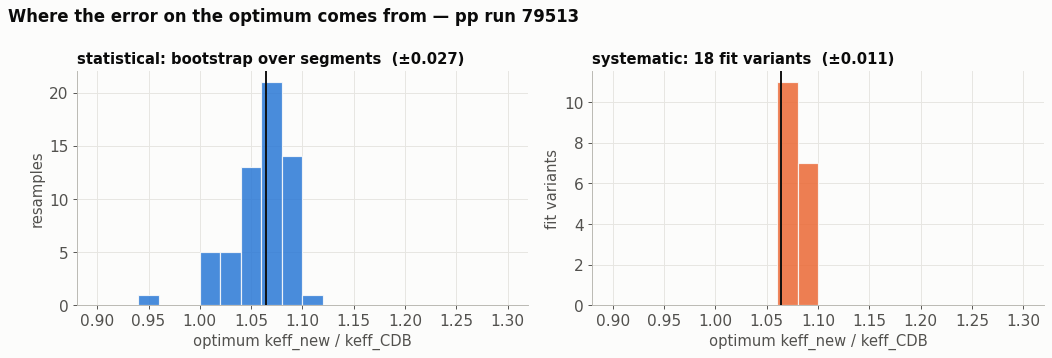

In [4]:
M.fig_error_budget('pp', 79513); plt.show()

### All measured optima
Black = mean of the width minimum (blue) and the significance maximum (violet), error bars from the bootstrap. A value at 0.95 means the optimum is at or below the lowest point of the scan (6 of 24 pp and 25 of 67 O+O runs).

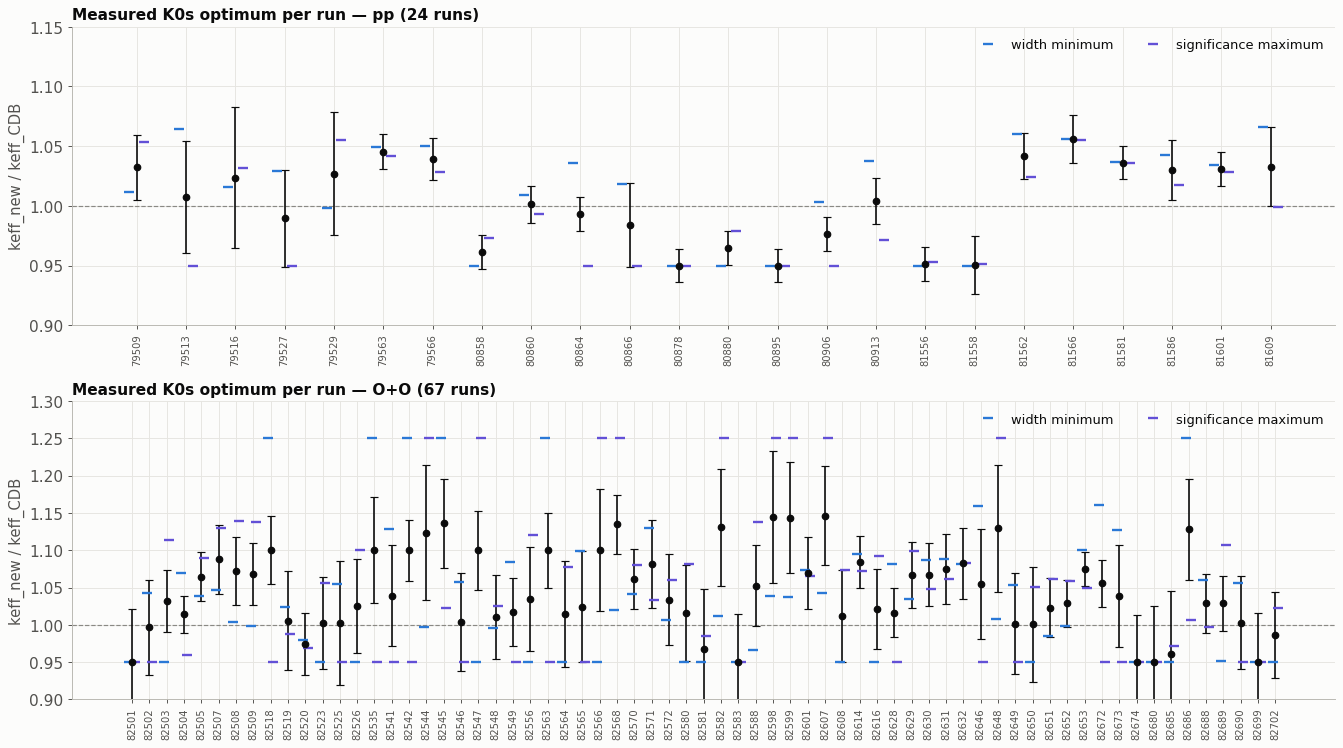

In [5]:
M.fig_opt_summary(); plt.show()

### 1.5  Why this K0s selection
A study of 12 selections on the pp runs (error of the optimum from the bootstrap; correlation with the predictors) showed that pT ≥ 1 GeV and a decay-length cut both improve pp, but **pT 1.0–3 GeV does not hold in O+O** (error 0.09 against 0.05, no correlation). The selection that works in both systems is all pT 0.5–3 GeV with Lxy > 5 cm; heavy tightening (DIRA > 0.99, tight combinations) throws away 70–85 % of the candidates and is worse.

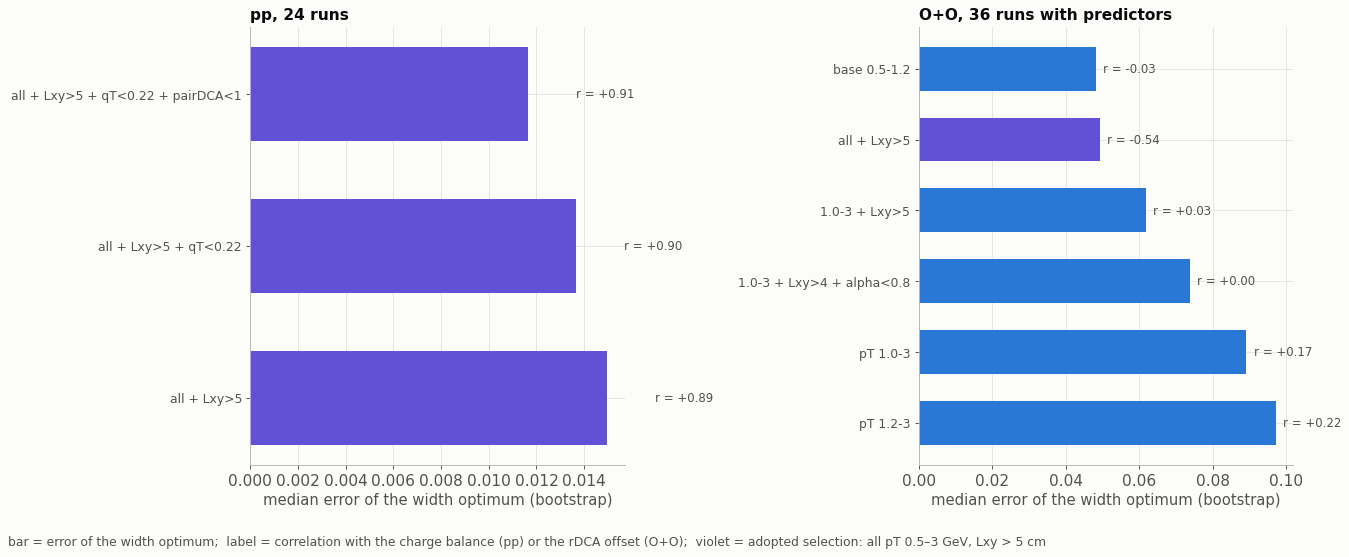

In [6]:
M.fig_selection_study(); plt.show()

### 1.6  O+O: is there a more robust K0s measure?  (last check before the re-reconstruction)

The per-run K0s optimum in O+O has an error of about 0.05, as large as the spread of the optima, so everything that follows is noise-limited. Before re-reconstructing we tried to find a more robust measure with four different kinds of test. All of them use the 67 O+O runs (or the 36 with a predictor), the same segments and events at every keff point.

**(a) 18 selections and three estimators.** Selections on top of the adopted one (decay length, qT, pair DCA, DIRA, alpha, track quality, npoints, proper decay length) and three estimators of the optimum: the width, the fitted significance, and a **fixed-window significance** (sideband-subtracted counts in a ±W window around the peak, no fit).

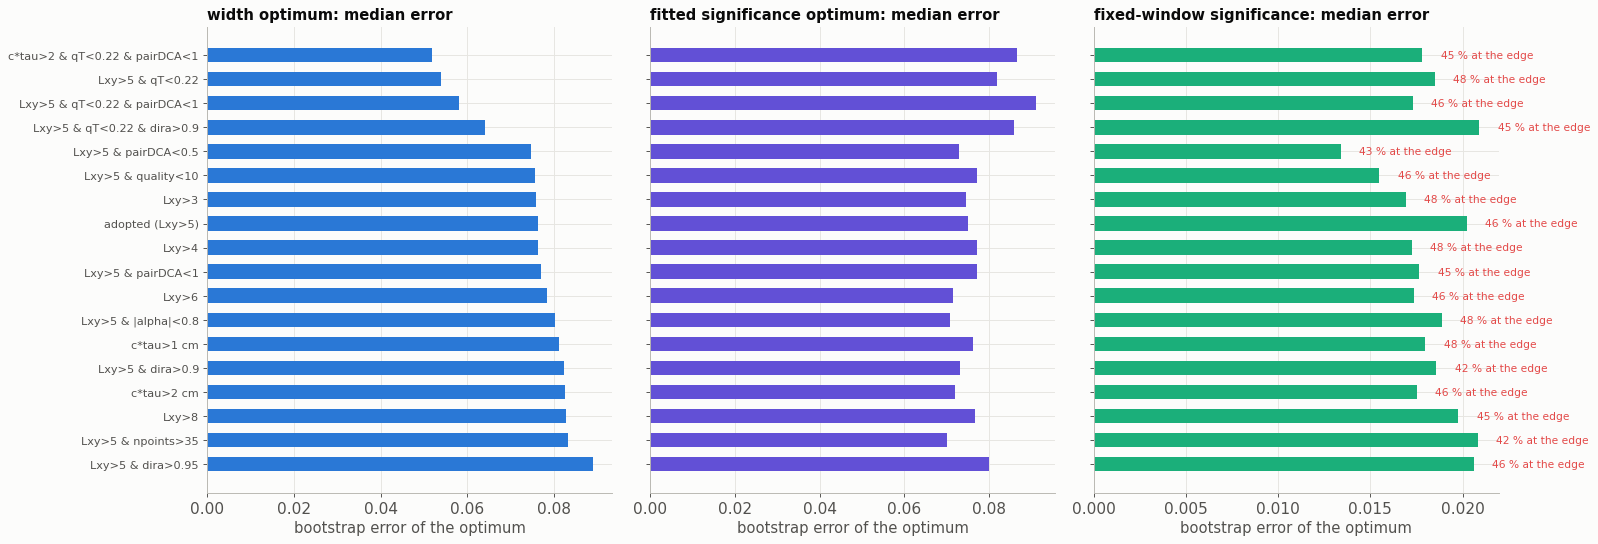

In [7]:
M.fig_cuts2(); plt.show()

* The error of the **fitted** optimum is about 0.075 for every selection (0.05–0.09): the cuts do not change it. The one exception is **qT < 0.22 GeV** (the K0s kinematic limit), which lowers the width error from 0.076 to 0.054 but not the significance error.
* The fixed-window significance has a 3–4× smaller error (green), but **45 % of the runs sit at the edge of the scan**, which clips the optimum and makes that error too small; its correlation with the rDCA offset jumps between −0.1 and −0.77 for neighbouring selections, so it is not stable.

**(b) Pool runs instead of cutting harder.** The 36 runs with a predictor are sorted by their CDB-reco rDCA offset and split into groups; the histograms of a group are added and one optimum is fitted per group (error: bootstrap over runs).

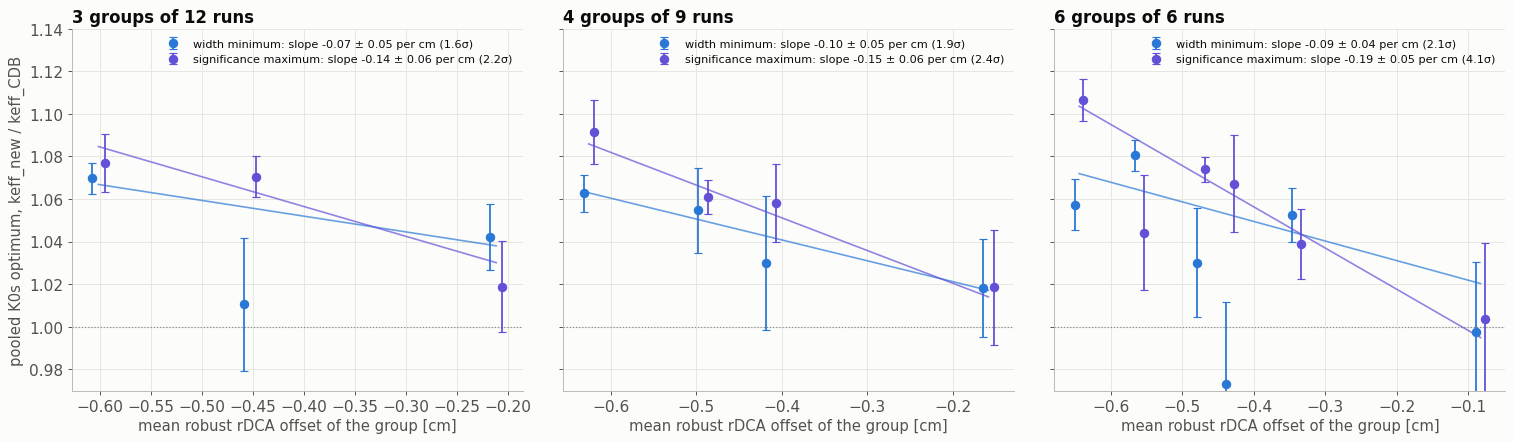

In [8]:
M.fig_pooled(); plt.show()

The pooled optimum falls as the offset becomes less negative, with the same direction for 3, 4 and 6 groups (width: −0.07 to −0.10 per cm, 1.6–2.1σ; significance: −0.14 to −0.19 per cm, 2.2–4.1σ). This is the clearest O+O evidence that the rDCA offset predicts the optimum; it is a trend of about 0.05–0.08 across the range, not a precise per-run calibration.

**(c) A cut search with a validation.** Round 1: 60 combinations of decay length (3–8 cm), qT, pair DCA and DIRA. Round 2: 28 combinations of dE/dx cuts on four base selections, including *dE/dx < 400 for pT < 1 GeV and < 300 above, per daughter* (absolute and scaled to the run). Each cut gets a **score** = the slope significance of the pooled optimum against the rDCA offset (mean of width and significance, 4 groups). To avoid choosing a cut that is just lucky, the best cut is chosen on one half of the runs and scored on the other half (24 random splits).

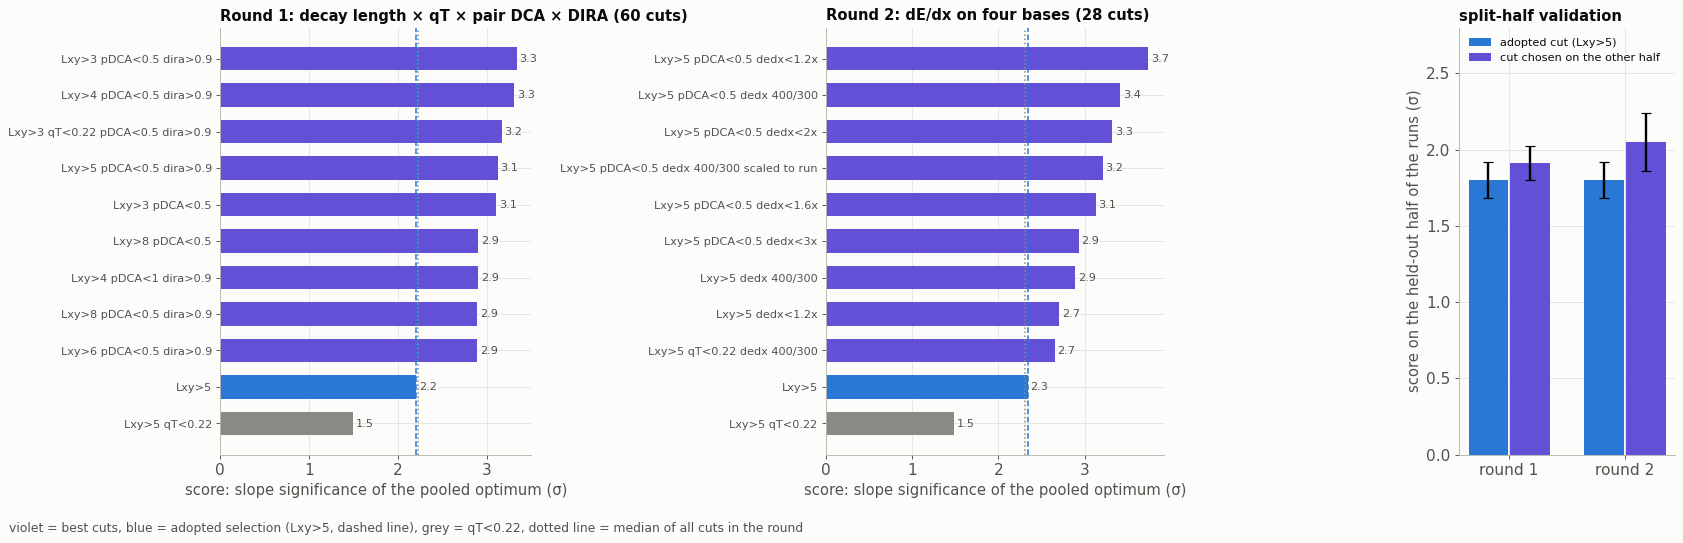

In [9]:
M.fig_cut_search(); plt.show()

* Round 1: the adopted Lxy > 5 cm scores 2.2 (rank 31 of 60, the median is 2.2). **pair DCA < 0.5 cm** is the one consistent direction (median score 2.7 with it, 1.9 without); **qT < 0.22 hurts** here (1.8 against 2.5).
* Round 2: all of the top six are pair DCA < 0.5 combined with a dE/dx cut (3.0–3.7); your 400/300 reaches 3.4, and it does as well as the run-scaled version (3.2). dE/dx alone on Lxy > 5 raises the score from 2.3 to 2.9.
* **Held-out check:** the chosen cut scores 1.91 ± 0.11 (round 1) and 2.05 ± 0.19 (round 2) on the half it was not chosen on, against 1.80 ± 0.12 for the adopted cut: a gain of 0.1–0.25σ ± 0.2σ, **not significant**. With 88 cuts tried, the top of the list is expected to look good by chance.
* The tighter cuts halve the statistics (about 3.3k instead of 6.9k candidates per run).

**(d) The dE/dx check.** An upper cut on the larger daughter dE/dx keeps most of the peak window and removes more of the sideband; but the dE/dx scale depends on the run (median ≈ 250 in three of the four runs shown, ≈ 309 at the highest current), which is why the run-scaled variant was tested.

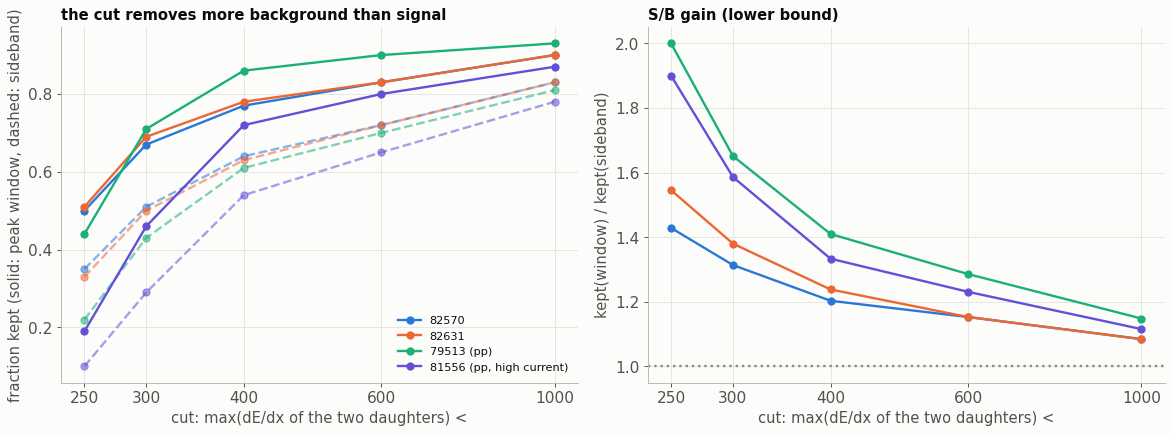

In [10]:
M.fig_dedx(); plt.show()

**(e) Does the significance depend on the yield?** No: the number of candidates changes by only a few percent between the keff points, while Z changes much more, and normalising the yield away moves the Z optimum by less than 0.01 (median). Both optima come from the peak shape.

,runs,candidate_count_range,Z_swing_max_over_min,optimum_shift_if_yield_removed_median,r_between_the_two_versions
system,,,,,
pp,24,0.986 … 1.010,1.064,0.009,0.938
O+O,67,0.952 … 1.027,1.510,0.004,0.934


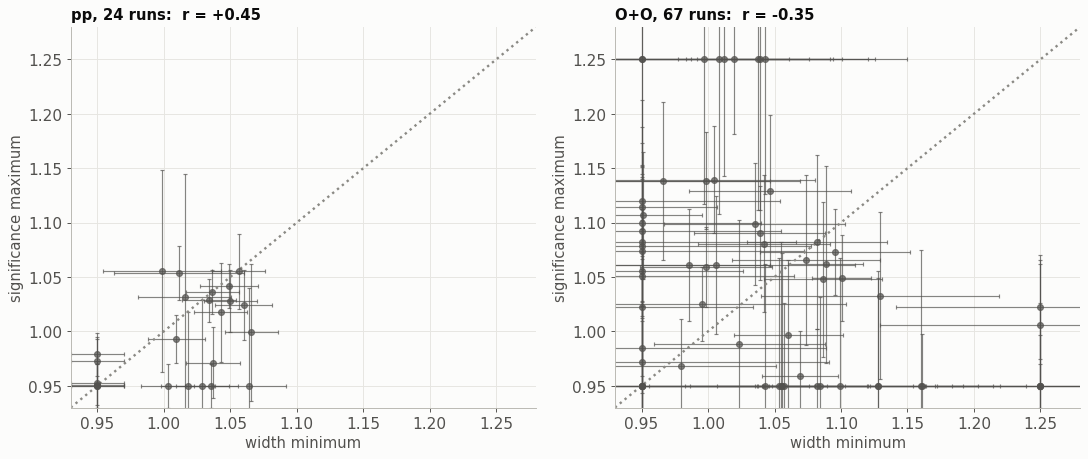

In [11]:
display(M.yield_check().round(3)); M.fig_sigz(); plt.show()

**What the width and the significance say about each other.** In pp the two optima are correlated (left, r = +0.45); in O+O they are **not** (right, r = −0.35), which is another face of the noise: each is a noisy estimate and the average of the two (used as the target) is the best we have.

**Conclusion of 1.6.** No cut gives a validated improvement of the O+O optimum. The consistent directions are pair DCA < 0.5 cm and a dE/dx cut (about +0.2–0.3σ on held-out runs, not significant) at the price of half the statistics; qT < 0.22 helps the width error but not the pooled trend. The adopted selection stays; the practical way to reduce the O+O noise is more statistics per run and pooling runs.

## 2  The robust rDCA offset

**What it measures.** If the space-charge correction (keff) is wrong, positive and negative tracks are displaced in opposite directions and the mean rDCA of the two charges differs. The offset q⁺ − q⁻ is the quantity that moves with keff (in the O+O scan it changes by about 6 cm per unit factor).

**Why "robust".** The rDCA depends on φ (beam spot, sector structure). For each charge we fit c + a·cos φ + b·sin φ with iterated 2.5σ clipping and take the constant c: the sine from the beam offset is removed, outliers such as sector edges are clipped, and the result is a φ-average. For O+O it is built from the tracks; for pp from the QA φ-profiles of the mean rDCA (valid bins only, error from a bootstrap over φ bins).

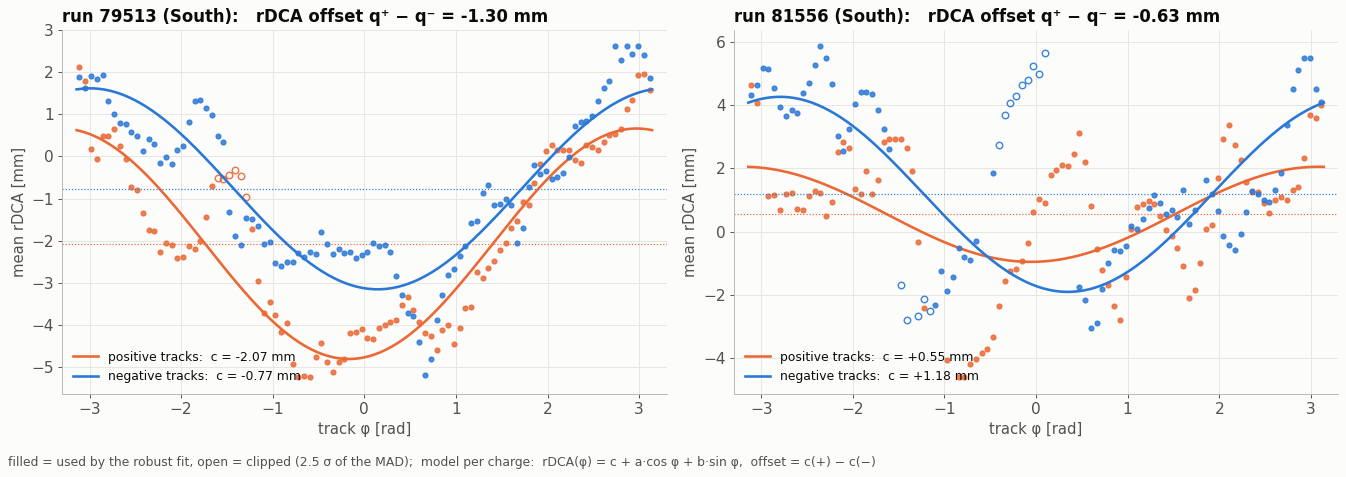

In [12]:
M.fig_rdca_method((79513, 81556)); plt.show()

The earlier pp observable was the value of a **harmonic fit at φ = 0**. At high current the φ-profiles have strong sector structure, the fit has χ²/ndf up to 245 and the value at φ = 0 is a smooth curve through a discontinuity (middle and right panels), so it was replaced by the robust offset (left).

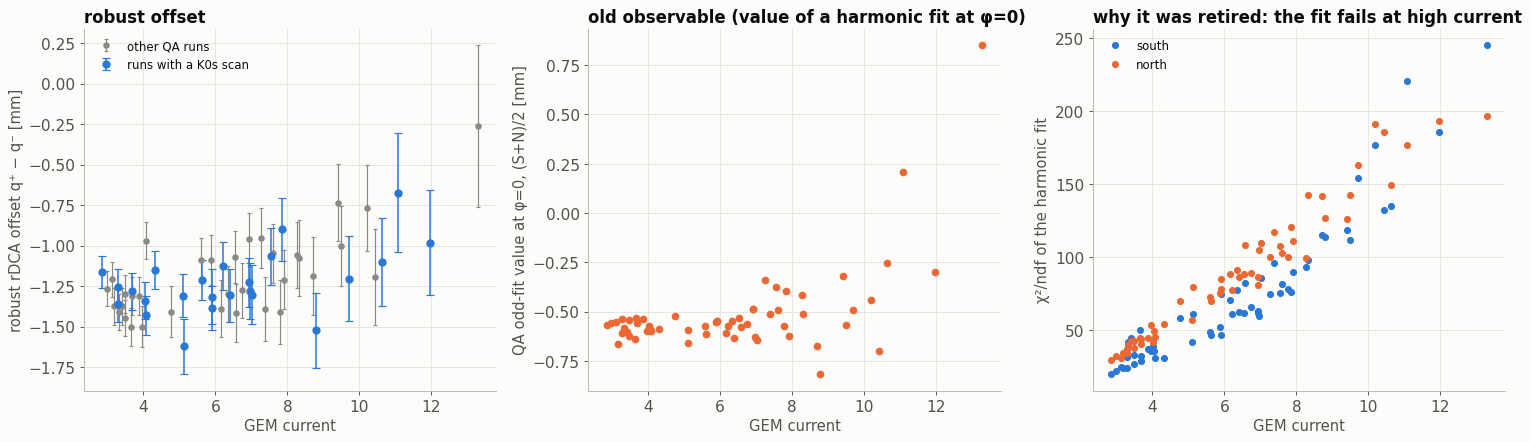

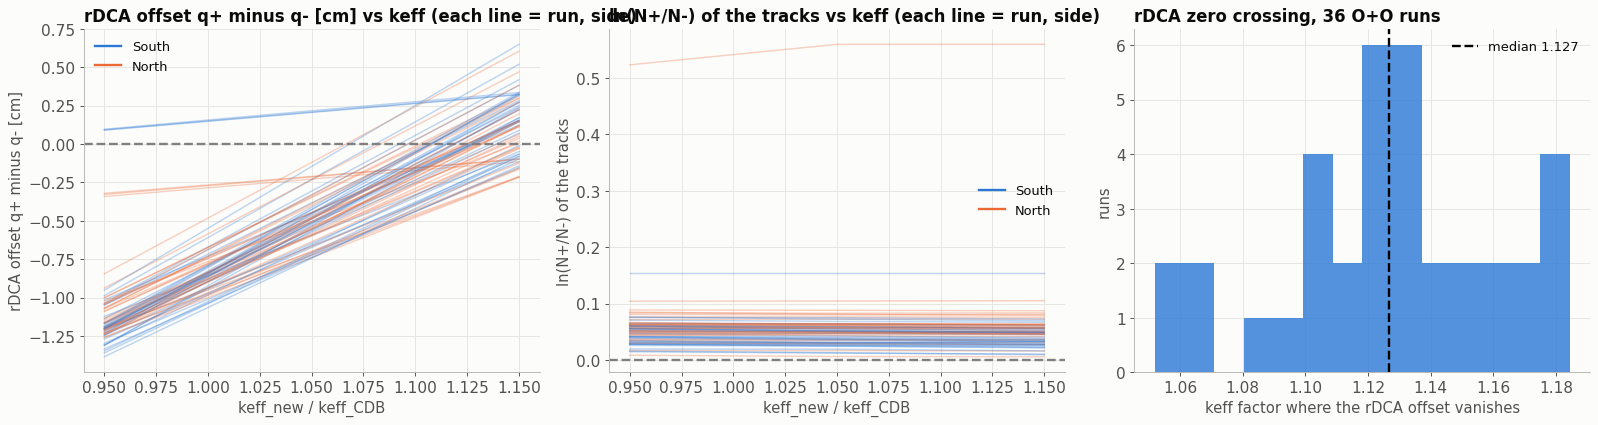

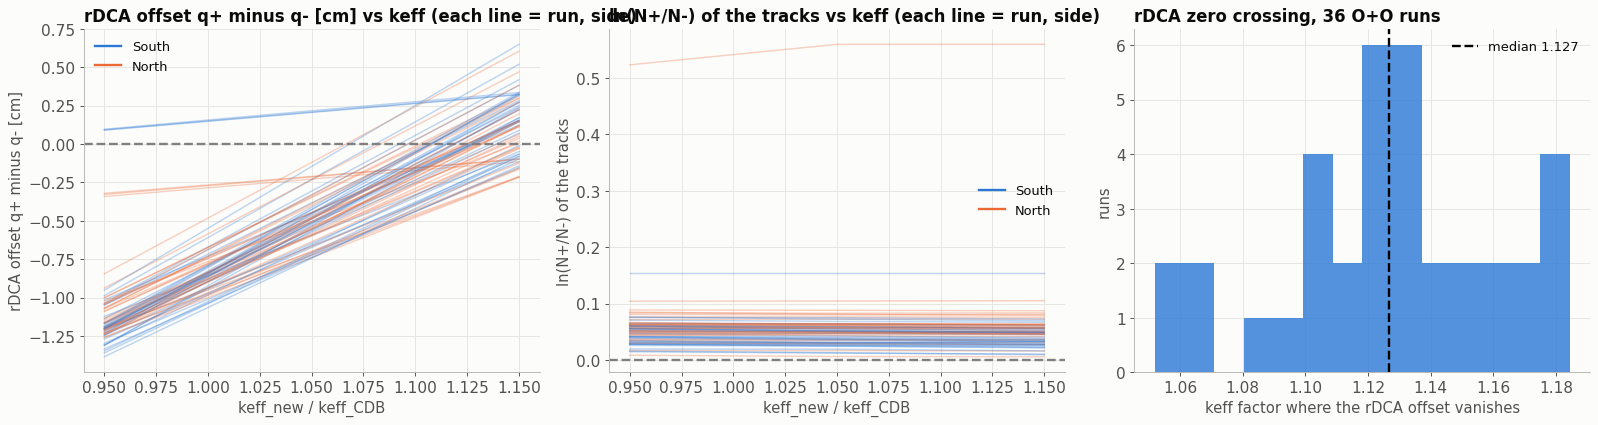

In [13]:
M.fig_rdca_vs_current(G, ppr, Opp); plt.show()
display(KP.fig_rdca_scan(D, Rm)); plt.show()

## 3  The charge balance

ln(N⁺/N⁻) of the tracks is not zero even for a perfect keff (antiprotons, secondaries from the material, dead maps), so the recipe uses a straight line **with an intercept**: only the run-to-run change enters. Its **pT dependence** `lnr_sl` = ln(N⁺/N⁻)[2–4 GeV] − ln(N⁺/N⁻)[0.5–1 GeV] is a curvature lever (a sagitta error grows with pT) and is the most precise observable: its error (Poisson, 0.015) is far below its spread between runs (0.2), against about 70 % for the rDCA. It follows the GEM current, but still predicts the K0s optimum after the current is removed (partial correlation +0.81).

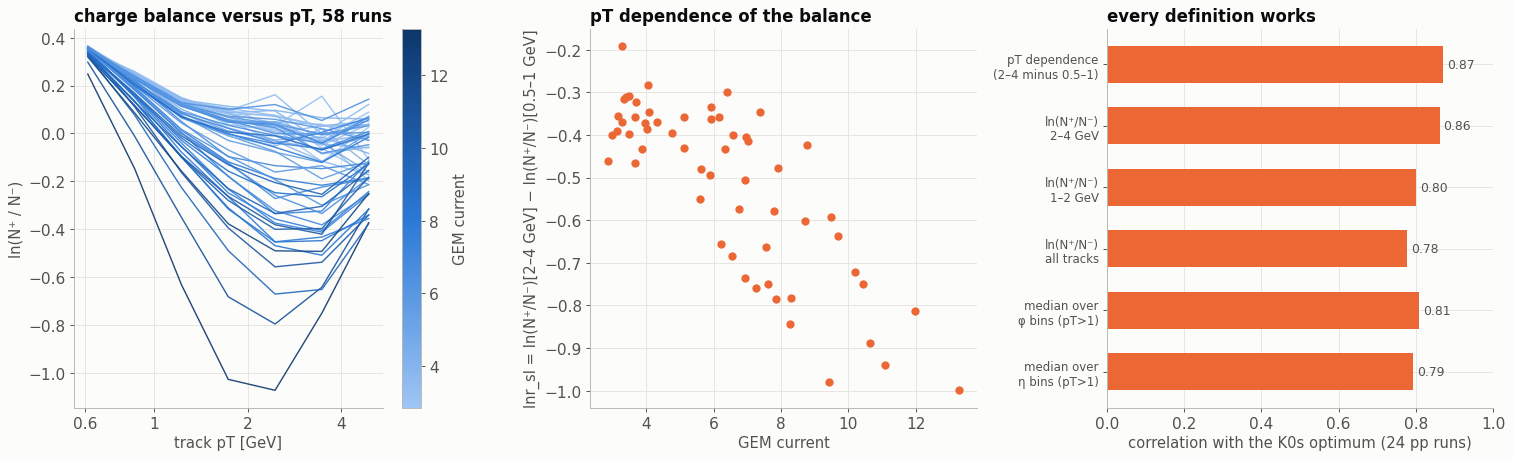

In [14]:
M.fig_balance_method(G); plt.show()

## 4  How the observables predict the K0s optimum

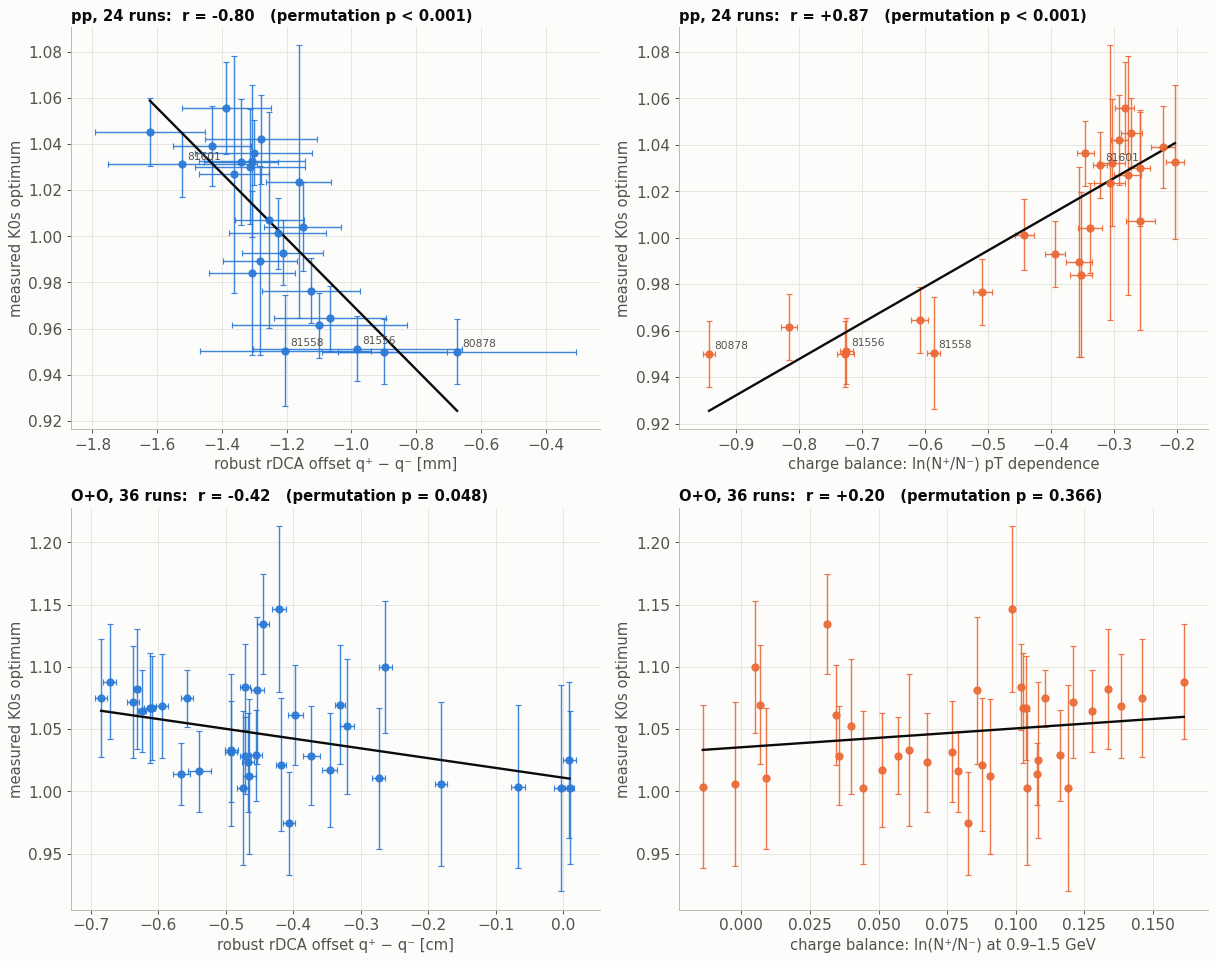

In [15]:
M.fig_corr_main(ms, ppr); plt.show()

In pp both observables are clearly correlated with the measured optimum (permutation p < 0.001). In O+O the rDCA offset has the same sign (r = −0.42, p = 0.048); the charge balance at 0.9–1.5 GeV shows nothing (r = +0.20). The O+O optimum per run has an error (median 0.046) larger than its spread (0.039), which dilutes every correlation.

### Which observable carries the signal?
The two observables are strongly correlated with each other (r = −0.84 in pp, −0.58 in O+O), so partial correlations show how much each adds once the other (and the GEM current or base keff) is known.

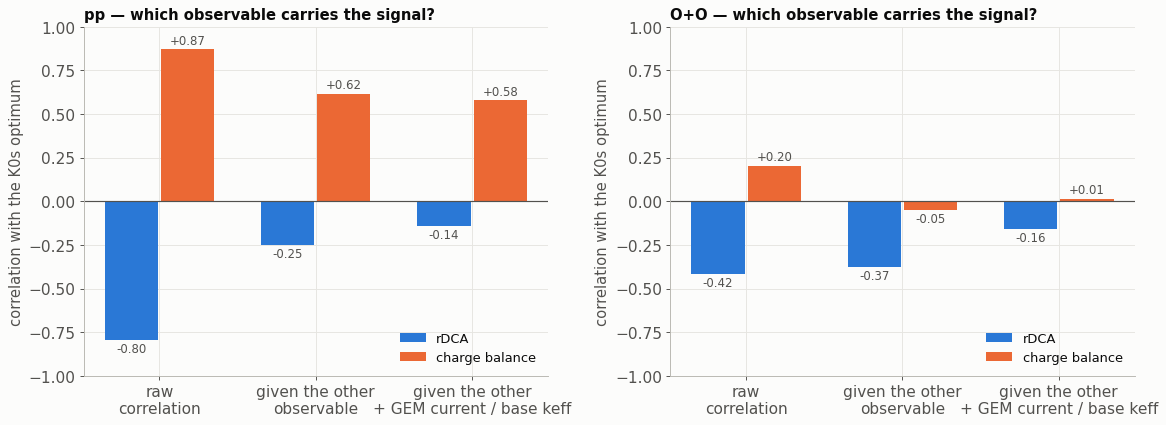

In [16]:
M.fig_partial(); plt.show()

### Leave-one-out prediction error
Each recipe is a weighted straight line fitted on all other runs and evaluated on the left-out run (weights 1/error² of the K0s optimum). The dashed red line is the rms K0s measurement error: a predictor cannot be better than that. The **weighted average** of the rDCA and balance predictions (weights ∝ 1/rms², no fitted parameters) avoids the overfitting of a two-variable regression.

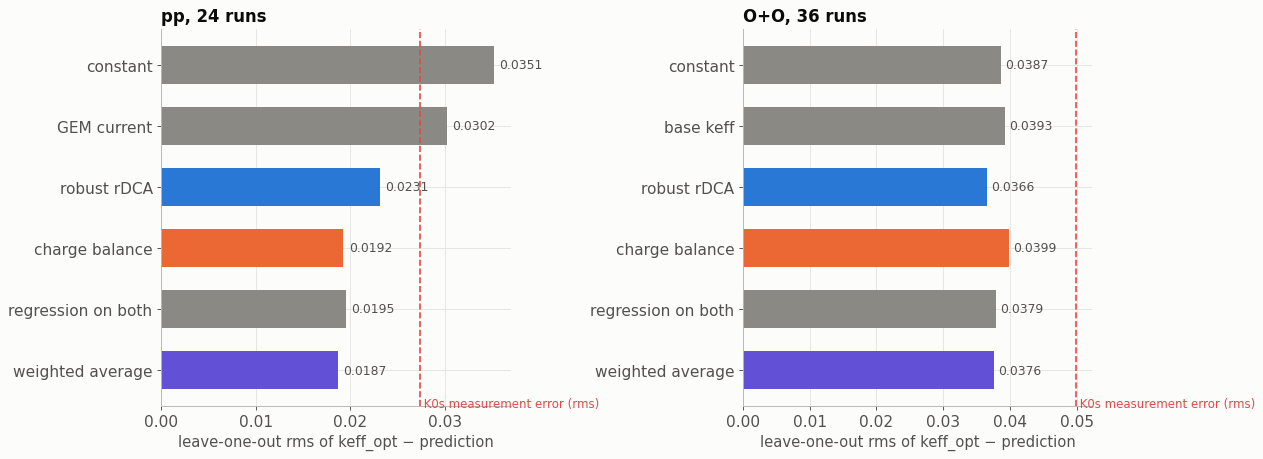

In [17]:
M.fig_loo_bars(); plt.show()

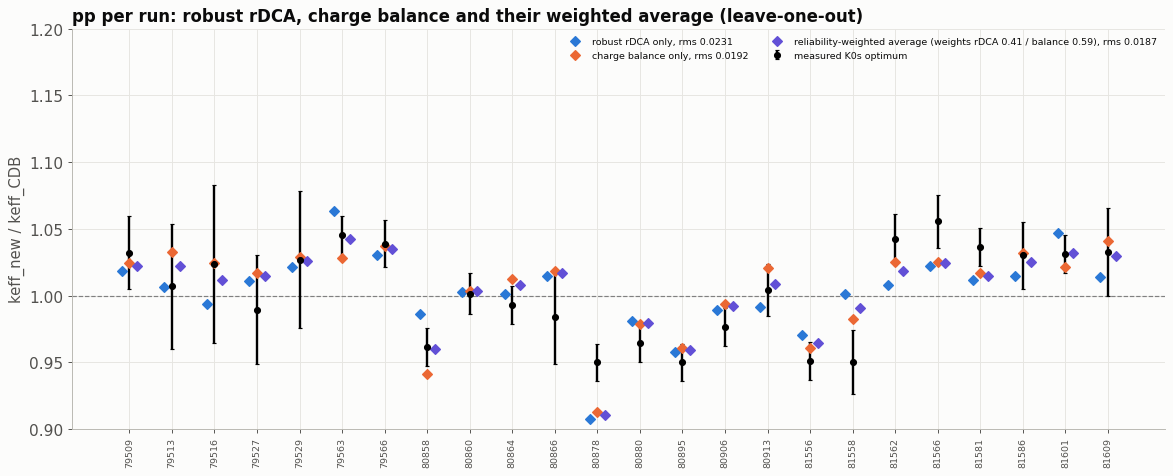

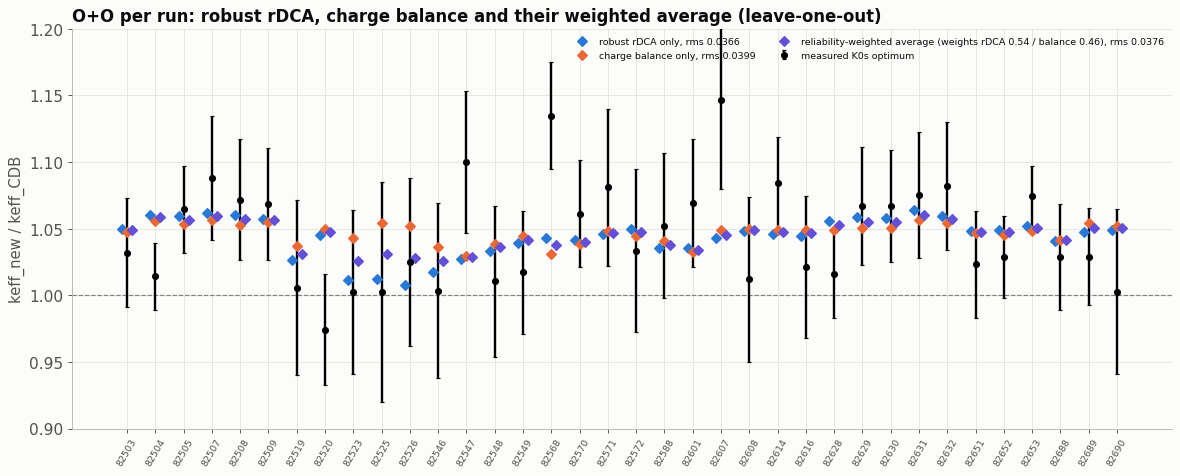

In [18]:
t, runs, y, e, _ = KB.pp_data(); pr_, pb_ = RC.loo(t.loc[runs, ['odd_rob']].values, y, e), RC.loo(t.loc[runs, ['lnr_sl']].values, y, e)
fig, pw_, w_ = KB.fig_wcomb(runs, y, e, pr_, pb_, 'pp per run: robust rDCA, charge balance and their weighted average (leave-one-out)'); plt.show()
to, runs_o, yo, eo, _ = KB.oo_data(); qr_, qb_ = RC.loo(to.loc[runs_o, ['odd0_cdb']].values, yo, eo), RC.loo(to.loc[runs_o, ['lnr_hi_cdb']].values, yo, eo)
fig, qw_, wo_ = KB.fig_wcomb(runs_o, yo, eo, qr_, qb_, 'O+O per run: robust rDCA, charge balance and their weighted average (leave-one-out)', rot=60); plt.show()

## 5  The recipe and the recommended keff for every pp run

* **pp, rDCA only:** keff_new/keff_CDB = 0.829 − 0.142 · rDCA_robust[mm].
* **pp, rDCA + charge-balance pT dependence:** 1.004 − 0.042 · rDCA_robust[mm] + 0.119 · lnr_sl, error propagated from the observable errors (open red = observable outside the range of the 24 calibration runs).
* **O+O:** keff_new/keff_CDB = 1.011 − 0.079 · rDCA_robust[cm] (a small gain over a constant 1.05; within the noise of the present K0s optima).

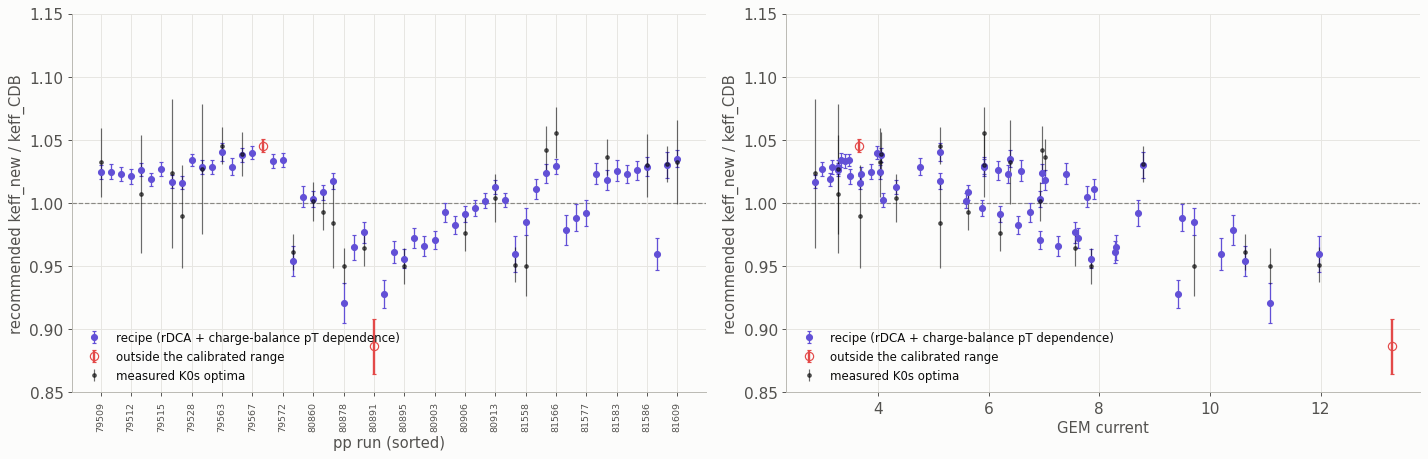

pp recipe: keff_new/keff_CDB = 1.004 -0.042 * rDCA_robust[mm] +0.119 * lnr_sl   (table: keff_recommendation_pp_58runs.csv)
pp: 0.829 -0.142 * [robust rDCA offset q+ minus q- from the QA φ-profiles [mm]]; leave-one-out rms 0.0231 vs constant 0.0351
O+O: 1.011 -0.079 * [robust rDCA offset q+ minus q- in the CDB reco [cm]]; leave-one-out rms 0.0366 vs constant 0.0387


In [19]:
fig, b58, out58 = M.fig_final_pp(); plt.show(); print('pp recipe: keff_new/keff_CDB = %.3f %+.3f * rDCA_robust[mm] %+.3f * lnr_sl   (table: keff_recommendation_pp_58runs.csv)' % tuple(b58))
for k, nm in (('pp', 'pp'), ('oo', 'O+O')): m = ms[k]; print('%s: %.3f %+.3f * [%s]; leave-one-out rms %.4f vs constant %.4f' % (nm, m['coef'][0], m['coef'][1], m['name'], m['rms_loo'], m['rms_const']))

## 6  Limits and next step
* **O+O is noise-limited:** the K0s optimum per run has an error of about 0.05, about the spread of the optima, so predictors cannot be told apart per run; a pooled test on many runs is needed.
* **Edge runs:** 6 of 24 pp and 25 of 67 O+O runs have their optimum at or below the lowest scan point (×0.95); their value is an upper bound.
* **Charge balance** may contain a physical charge asymmetry that follows the run conditions; the π⁺/π⁻ ratio of the K0s daughters is a charge-symmetric check.
* **Next:** re-reconstruct pp and O+O on the same segments in three configurations: (1) CDB, (2) new map with CDB keff, (3) new map with the recipe keff, and compare the K0s run by run (paired).